In [1]:
import sys
import os
import numpy as np
import scipy as sp
import pandas as pd
from matplotlib import pyplot as plt

from sklearn.cross_decomposition import CCA


sys.path.append(os.path.join(os.getcwd(), '../'))
from utils_fly import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/train_utils.py'>

In [8]:
dims = 3
dims_preca = 5

read_ids = list(range(0, 12+1))
# read_ids = [0,	# paper
# 			1,	# nice states
# 			2,	# nice manifold
# 			5,	# variety
# 			6,	# nice quiescence
# 			7,	# nice states
# 			9,	# nice heatmap
# 			11]	# variety
# read_ids = [0]
plot_id = 0

In [9]:
# read

path = os.path.join(read_utils.get_data_path(), 'brain')
(file_ids, filenames,
 traces,
 states, markers) = read_utils.get_datas(path, read_ids)

# # clear nan values
# for i in range(len(file_ids)):
# 	mask = markers[i].notna().all(axis=1)
#
# 	traces[i] = traces[i][mask]
# 	markers[i] = markers[i][mask]
# 	states[i] = states[i][mask]
#
# 	#filenames[i] = filenames[i][mask]

# naive ID unknown neurons
for i in range(len(file_ids)):
	traces[i].columns = pd.Index([
		f'{file_ids[i]:02d}_{n_id:03d}' if empty else label for n_id, (label, empty) in enumerate(zip(traces[i].columns, traces[i].columns == ''))
	])

In [10]:
# prep

def highpass_butter(x, fs, cutoff_hz, order=4, axis=0):
    return sp.signal.sosfiltfilt(sp.signal.butter(order, cutoff_hz, btype='highpass', fs=fs, output='sos'), x, axis=axis)

sampling_rates = [read_utils.get_sampling_rate(os.path.join(path, filenames[file_ids.index(file_id)])) for file_id in file_ids]

traces = [pd.DataFrame(highpass_butter(trace.values, sr, 1 / 100), columns=trace.columns) for trace, sr in zip(traces, sampling_rates)]

markers_grad = [pd.DataFrame(np.gradient(marker.values, axis=0), columns=marker.columns) for marker in markers]

In [20]:
selection_bhl = ['walk', 'still', 'front-groom', 'back-groom', 'abdomen-move', 'background']

plot_idx = file_ids.index(plot_id)

# states = [ds[selection_bhl] for ds in states]

In [21]:
(modes_manifold, modes_manifold_b,
 recos_manifold, recos_manifold_b,
 loads_cca_man, loads_cca_man_b,
 vars_expl_mans, vars_expl_mans_rs) = train_utils.get_manifolds_cca(traces,
																	[s[selection_bhl] for s in states],
																	zscore=(False, False),
																	n_cv=dims, n_pc=dims_preca)

In [22]:
save = True

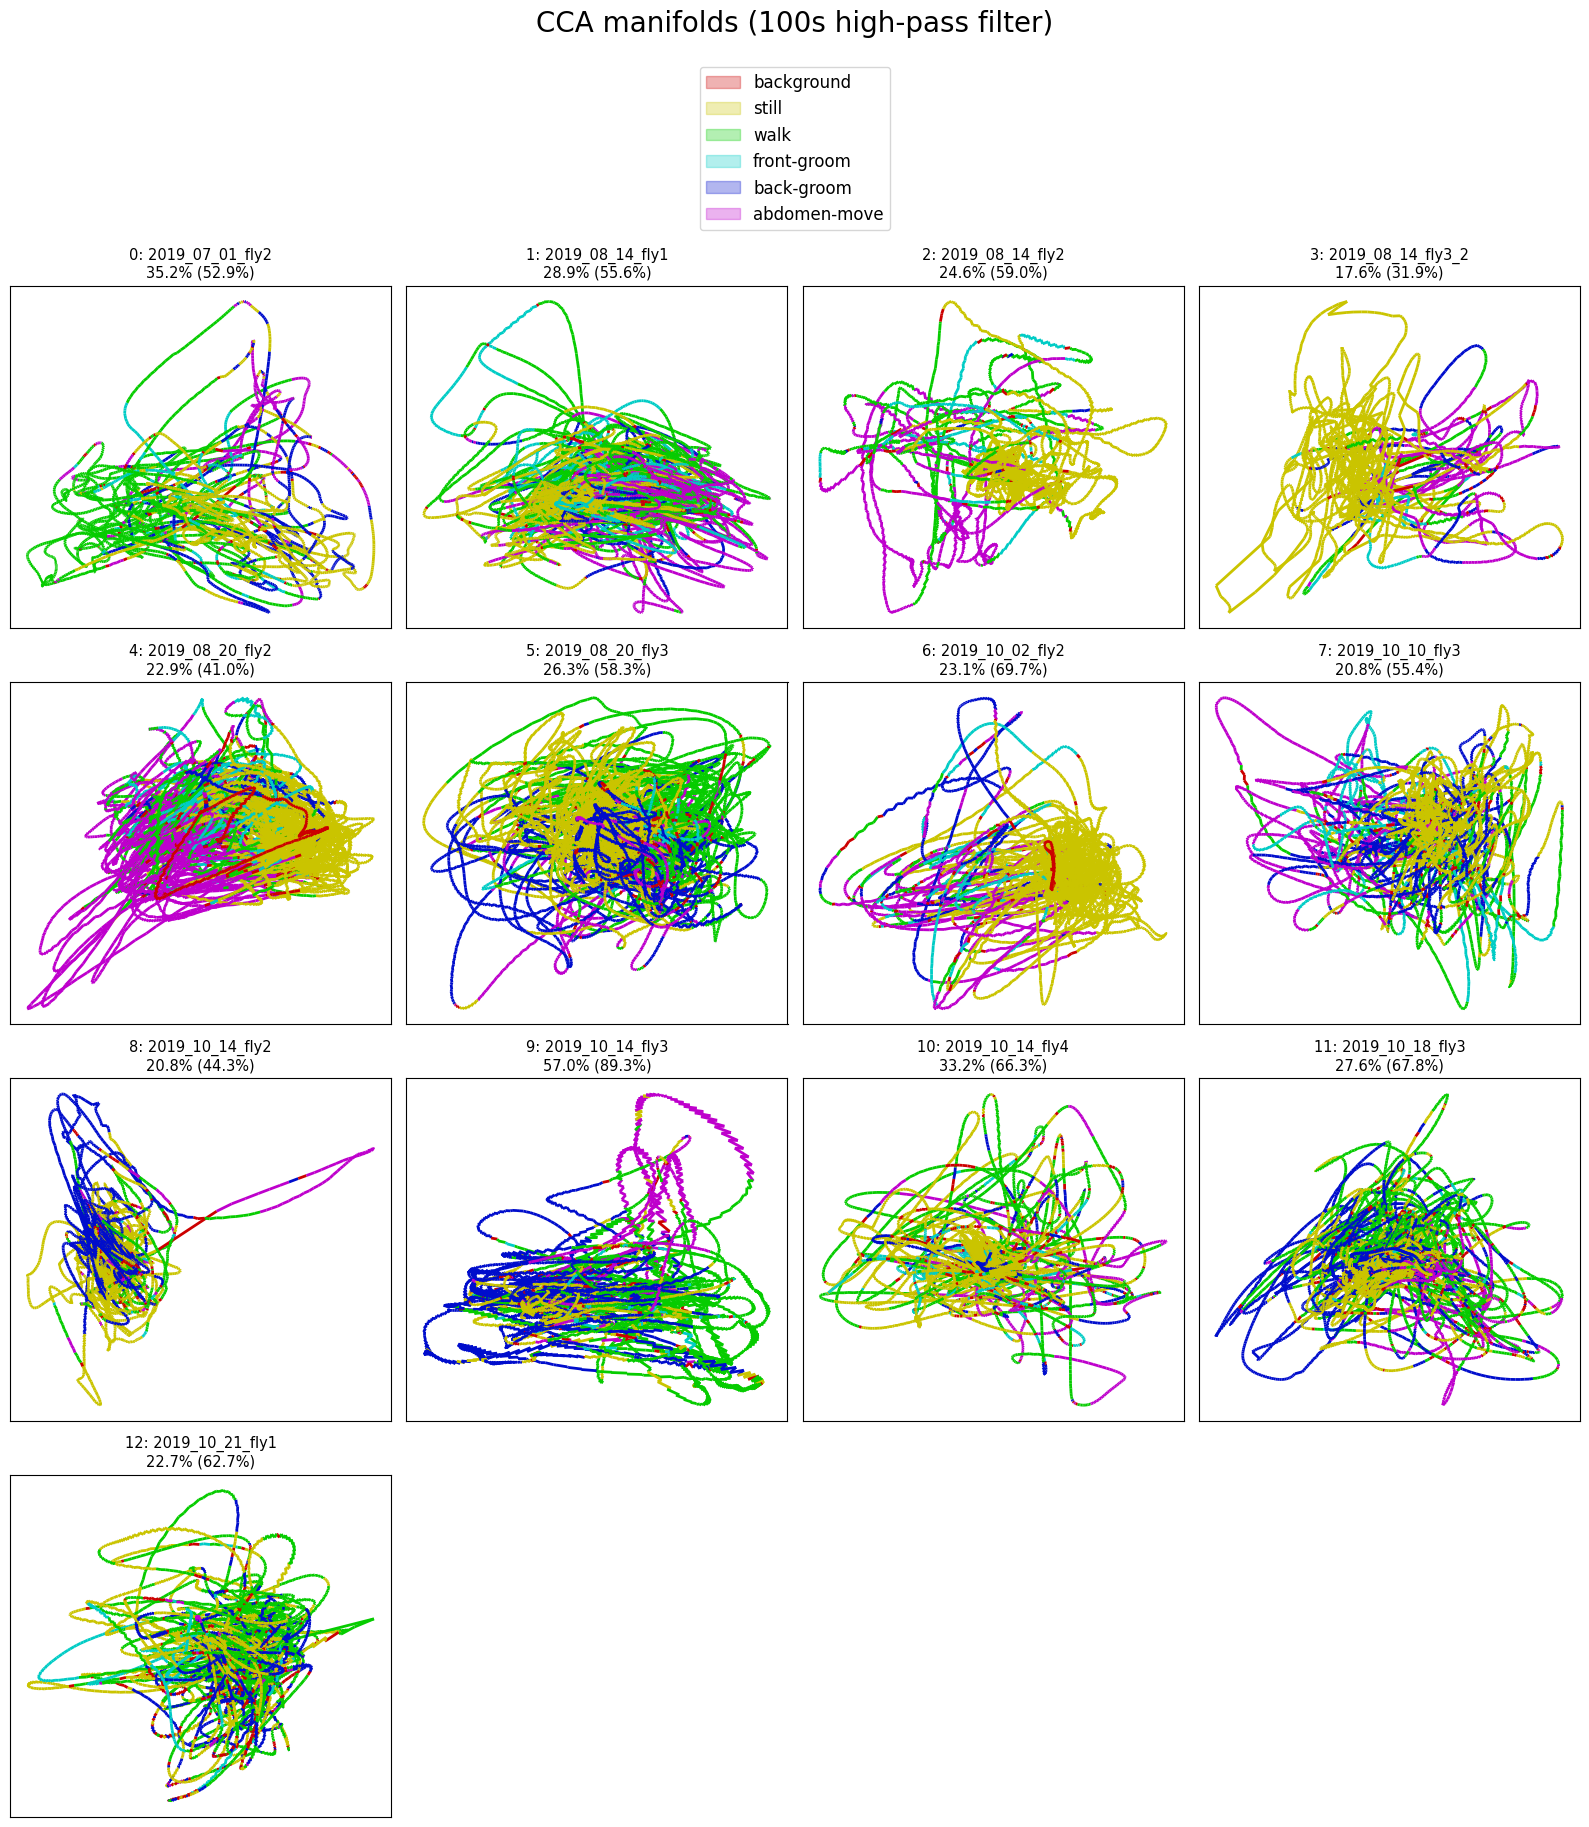

In [23]:
plot_utils.plot_manifolds([f'{str(file_id)}: {filenames[file_ids.index(file_id)]}' for file_id in file_ids],
						  modes_manifold, states,
						  [vx[:2] for vx in vars_expl_mans], [vx[:2] for vx in vars_expl_mans_rs] if dims_preca > 0 else None,
						  title='CCA manifolds (100s high-pass filter)', top_space=2.5,
						  save_path=f'../../out/plots/manifolds/{dims}-dim-CCA' if save else None)

In [ ]:
# plot_utils.plot_manifolds_3d([f'{str(file_id)}: {filenames[file_ids.index(file_id)]}' for file_id in file_ids],
# 							 modes_manifold, states,
# 							 [vx[:3] for vx in vars_expl_mans], [vx[:3] for vx in vars_expl_mans_rs] if dims_preca > 0 else None,
# 							 title='CCA manifolds (100s high-pass filter)', top_space=3,
# 							 save_path=f'../../out/plots/manifolds/{dims}-dim-CCA_3d' if save else None)

In [ ]:
for file_id in file_ids:
	corrs = [
		np.corrcoef(modes_manifold[file_ids.index(file_id)].values[:, i], modes_manifold_b[file_ids.index(file_id)].values[:, i])[0, 1] for i in range(modes_manifold[file_ids.index(file_id)].values.shape[1])
	]
	print(f'{file_id}: {filenames[file_ids.index(file_id)]}')
	for i, corr in enumerate(corrs):
		print(f'\tCV{i}: {corr:.2f}')

In [ ]:
for i, trace in enumerate(traces):
	print(np.mean(trace.values, axis=0))

In [ ]:
traces_residual = [pd.DataFrame(t.values - t_rec.values, columns=t.columns) for t, t_rec in zip(traces, recos_manifold)]

for i, trace in enumerate(traces_residual):
	print(np.mean(trace.values, axis=0))

In [ ]:
raise Exception

In [ ]:
# traces_manifolds_indices = [np.argsort(xloads_cca_man[0, :]) for xloads_cca_man in loads_cca_man]
#
# traces_sorted = [t.iloc[:, t_man_idx.tolist()] for t, t_man_idx in zip(traces, traces_manifolds_indices)]
#
# traces_manifolds_sorted = [t_man.iloc[:, t_man_idx.tolist()] for t_man, t_man_idx in zip(recos_manifold, traces_manifolds_indices)]
#
# traces_residuals_sorted_by_manifold = [t_res.iloc[:, t_man_idx.tolist()] for t_res, t_man_idx in zip(traces_residuals, traces_manifolds_indices)]